In [4]:
# ==========================================
# AI-POWERED FX RISK INTELLIGENCE PLATFORM
# Week 3 - Session 2
# Random Forest Modelling
# ==========================================

%pip install pandas numpy scikit-learn matplotlib seaborn joblib

# Data manipulation
import pandas as pd 
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.ensemble import RandomForestRegressor

# Model evaluation
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

# Baseline model
from sklearn.dummy import DummyRegressor

# Saving models and outputs
import joblib
from pathlib import Path

# Warnings 
import warnings 
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Libraries successfully imported.")

Note: you may need to restart the kernel to use updated packages.
Libraries successfully imported.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Set project directory
PROJECT_ROOT = Path.cwd()

# Locate project root if notebook is running inside notebooks
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load engineered dataset
data_path = PROJECT_ROOT / "data" / "processed" / "ml_features.csv"
df = pd.read_csv(data_path)

# Convert Datae into datetime format 
df["Date"] = pd.to_datetime(df["Date"])

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Display dataset
print("Dataset successfully loaded.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset successfully loaded.
Dataset shape: (1235, 25)


,Date,GBPUSD_Return_1D,GBPUSD_Return_5D,GBPUSD_Volatility_5D,GBPUSD_Volatility_20D,GBPUSD_Volatility_60D,GBPUSD_Momentum_5D,GBPUSD_Momentum_20D,EURUSD_Return_1D,EURUSD_Return_5D,EURUSD_Volatility_5D,EURUSD_Volatility_20D,EURUSD_Volatility_60D,EURUSD_Momentum_5D,EURUSD_Momentum_20D,USDJPY_Return_1D,USDJPY_Return_5D,USDJPY_Volatility_5D,USDJPY_Volatility_20D,USDJPY_Volatility_60D,USDJPY_Momentum_5D,USDJPY_Momentum_20D,GBPUSD_Target_Volatility_5D,EURUSD_Target_Volatility_5D,USDJPY_Target_Volatility_5D
0,2022-01-26,0.001594,-0.006580,0.002668,0.003079,0.003862,-0.006580,0.005769,-0.001730,-0.002216,0.002160,0.003748,0.003727,-0.002216,-0.000904,-0.001193,-0.005927,0.001904,0.002915,0.003395,-0.005927,-0.007824,0.004777,0.006427,0.004670
1,2022-01-27,-0.003165,-0.010330,0.002516,0.002972,0.003805,-0.010330,-0.002280,-0.005397,-0.008804,0.002817,0.003803,0.003753,-0.008804,-0.010265,0.007429,0.003271,0.004222,0.003381,0.003527,0.003271,-0.001975,0.004463,0.005866,0.003583
2,2022-01-28,-0.005918,-0.015396,0.002883,0.003243,0.003462,-0.015396,-0.008153,-0.008583,-0.014736,0.004195,0.004179,0.003848,-0.014736,-0.015717,0.005500,0.011922,0.004057,0.003600,0.003583,0.011922,0.002512,0.001765,0.004519,0.003382
3,2022-01-31,0.001126,-0.011246,0.003447,0.003223,0.003463,-0.011246,-0.008793,0.000480,-0.016673,0.003612,0.004020,0.003844,-0.016673,-0.019439,-0.000780,0.012981,0.003805,0.003603,0.003558,0.012981,0.001042,0.003996,0.004230,0.003635
4,2022-02-01,0.003133,-0.003254,0.003761,0.003263,0.003413,-0.003254,-0.002810,0.006929,-0.008344,0.005921,0.004185,0.003952,-0.008344,-0.006423,-0.001223,0.009736,0.004184,0.003595,0.003551,0.009736,-0.001795,0.003984,0.004947,0.003650


In [10]:
# Check dataset
print("Dataset information:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1235 entries, 0 to 1234
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Date                         1235 non-null   datetime64[us]
 1   GBPUSD_Return_1D             1235 non-null   float64       
 2   GBPUSD_Return_5D             1235 non-null   float64       
 3   GBPUSD_Volatility_5D         1235 non-null   float64       
 4   GBPUSD_Volatility_20D        1235 non-null   float64       
 5   GBPUSD_Volatility_60D        1235 non-null   float64       
 6   GBPUSD_Momentum_5D           1235 non-null   float64       
 7   GBPUSD_Momentum_20D          1235 non-null   float64       
 8   EURUSD_Return_1D             1235 non-null   float64       
 9   EURUSD_Return_5D             1235 non-null   float64       
 10  EURUSD_Volatility_5D         1235 non-null   float64       
 11  EURUSD_Volatility_20D        1235

In [11]:
# Define target variable 
target_column = "GBPUSD_Target_Volatility_5D"

# Identify all target columns 
target_columns = ["GBPUSD_Target_Volatility_5D","EURUSD_Target_Volatility_5D","USDJPY_Target_Volatility_5D"]

# Select feature variables 
X = df.drop(columns=target_columns)

# Select prediction target
y = df[target_column]

# Remove rows with missing target values
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Display dataset dimensions
print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("\nTarget variable:", target_column)
print("Missing target values:", y.isna().sum())

Feature dataset shape: (1235, 22)
Target dataset shape: (1235,)

Target variable: GBPUSD_Target_Volatility_5D
Missing target values: 0


In [13]:
# Calculate split boundaires 
n = len(df)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

# Five-observation gap tp avoid overlapping target horizons
gap = 5

# Training dataset
X_train = X.iloc[:train_end - gap]
y_train = y.iloc[:train_end - gap]

# Validation dataset
X_val = X.iloc[train_end:validation_end - gap]
y_val = y.iloc[train_end:validation_end - gap]

# Testing dataset
X_test = X.iloc[validation_end:]
y_test = y.iloc[validation_end:]

# Display dataset sizes
print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))
print("\nTraining period:")
print(df.iloc[:train_end - gap]["Date"].min(), "to", df.iloc[:train_end - gap]["Date"].max())
print("\nValidation period:")
print(df.iloc[train_end:validation_end - gap]["Date"].min(), "to", df.iloc[train_end:validation_end - gap]["Date"].max())
print("\nTesting period:")
print(df.iloc[validation_end:]["Date"].min(), "to", df.iloc[validation_end:]["Date"].max())

Training observations: 859
Validation observations: 180
Testing observations: 186

Training period:
2022-01-26 00:00:00 to 2025-05-15 00:00:00

Validation period:
2025-05-23 00:00:00 to 2026-02-02 00:00:00

Testing period:
2026-02-10 00:00:00 to 2026-10-27 00:00:00


In [16]:
# Remove Date column from training and validation features
X_train = X_train.drop(columns=["Date"], errors="ignore")
X_val = X_val.drop(columns=["Date"], errors="ignore")

print("Date column removed successfully.")

print("\nTraining dataset shape:", X_train.shape)
print("Validation dataset shape:", X_val.shape)

Date column removed successfully.

Training dataset shape: (859, 21)
Validation dataset shape: (180, 21)


In [17]:
# Confirm all features are numerical
print("Non-numerical training columns:")
print(X_train.select_dtypes(exclude=["number"]).columns.tolist())

print("\nNon-numerical validation columns:")
print(X_val.select_dtypes(exclude=["number"]).columns.tolist())

Non-numerical training columns:
[]

Non-numerical validation columns:
[]


In [18]:
# Initialise Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=200,max_depth=10,min_samples_split=5,min_samples_leaf=2,random_state=42,n_jobs=-1)
print("Random Forest model successfully initialled.")

# Train the Random Forest model
rf_model.fit(X_train, y_train)
print("Random Forest model successfully trained.")

# Generate predictions on validation dataset 
y_val_pred = rf_model.predict(X_val)

# Create comparison dataframe
validation_results = pd.DataFrame({"Actual_Volatility": y_val.values, "Predicted_Volatility": y_val_pred})
display(validation_results.head(10))

Random Forest model successfully initialled.
Random Forest model successfully trained.


,Actual_Volatility,Predicted_Volatility
0,0.006116,0.005834
1,0.004521,0.006107
2,0.005616,0.006021
3,0.005355,0.005545
4,0.004019,0.005213
5,0.003620,0.005493
6,0.003800,0.005353
7,0.002296,0.005313
8,0.002731,0.005475
9,0.003428,0.005711


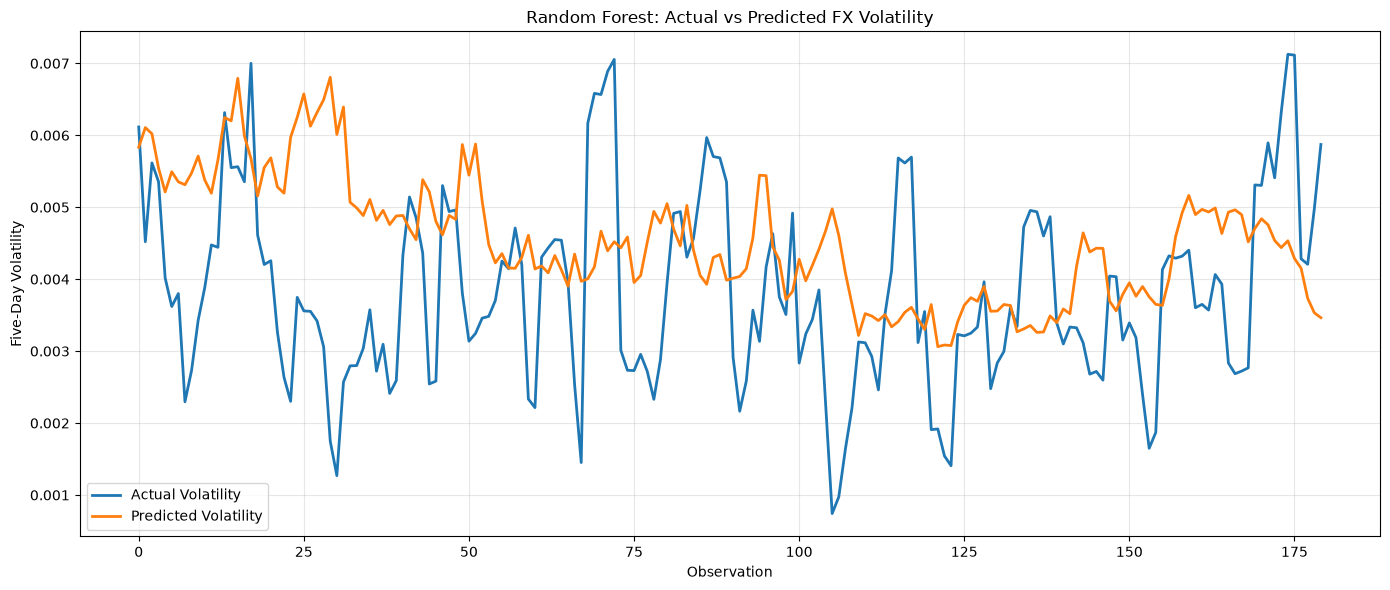

In [21]:
# Visualisation of actual vs predicted volatility
plt.figure(figsize=(14,6))
plt.plot(validation_results["Actual_Volatility"],label="Actual Volatility",linewidth=2)
plt.plot(validation_results["Predicted_Volatility"],label="Predicted Volatility",linewidth=2)
plt.title("Random Forest: Actual vs Predicted FX Volatility")
plt.xlabel("Observation")
plt.ylabel("Five-Day Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# Calculate validation metrics
mae = mean_absolute_error(y_val, y_val_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
r2 = r2_score(y_val, y_val_pred)

# Display results
print("Random Forest Validation Results:")

print(f"MAE: {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²: {r2:.4f}")

Random Forest Validation Results:
MAE: 0.001357
RMSE: 0.001677
R²: -0.6321


In [23]:
# Create baseline model
baseline_model = DummyRegressor(strategy="mean")

# Train baseline using training data
baseline_model.fit(X_train, y_train)

# Generate validation predictions
baseline_predictions = baseline_model.predict(X_val)

# Calculate baseline metrics
baseline_mae = mean_absolute_error(y_val, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_val, baseline_predictions))
baseline_r2 = r2_score(y_val, baseline_predictions)

print("Baseline Model Results:")

print(f"MAE: {baseline_mae:.6f}")
print(f"RMSE: {baseline_rmse:.6f}")
print(f"R²: {baseline_r2:.4f}")

Baseline Model Results:
MAE: 0.001578
RMSE: 0.001842
R²: -0.9709


In [24]:
# Extract feature importance
feature_importance = pd.DataFrame({"Feature": X_train.columns, "Importance": rf_model.feature_importances_})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
display(feature_importance)

,Feature,Importance
3,GBPUSD_Volatility_20D,0.338400
11,EURUSD_Volatility_60D,0.085136
4,GBPUSD_Volatility_60D,0.067192
18,USDJPY_Volatility_60D,0.060687
10,EURUSD_Volatility_20D,0.059736
20,USDJPY_Momentum_20D,0.042458
6,GBPUSD_Momentum_20D,0.039601
5,GBPUSD_Momentum_5D,0.035844
2,GBPUSD_Volatility_5D,0.032973
17,USDJPY_Volatility_20D,0.031703


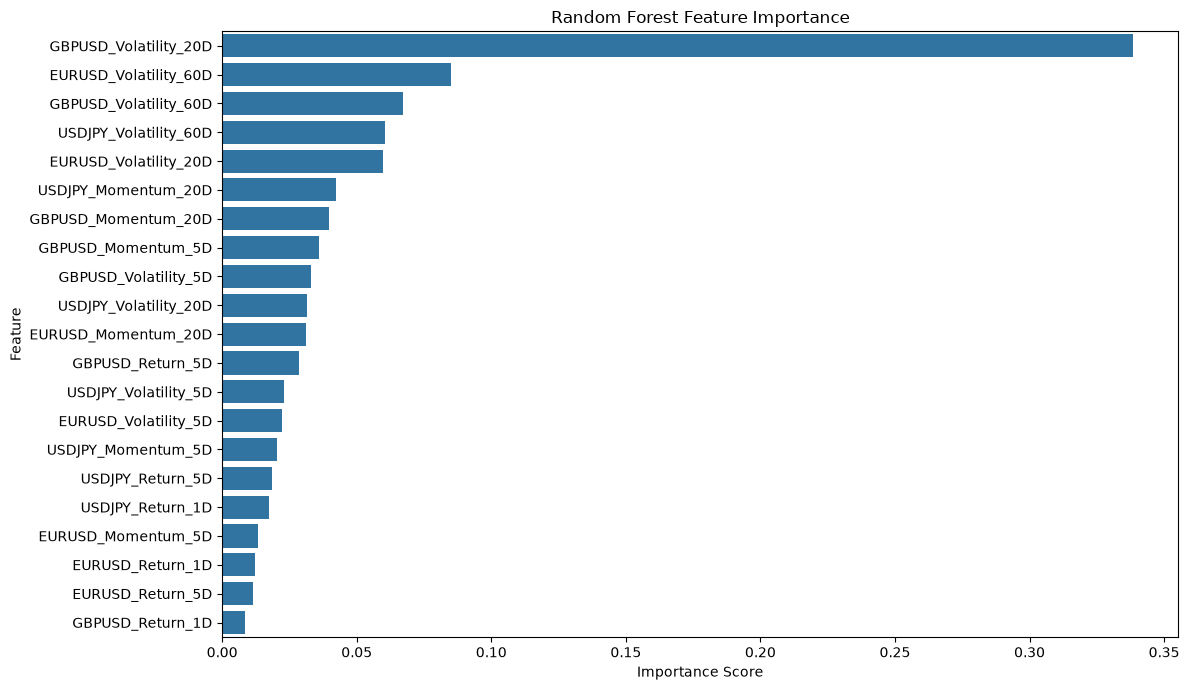

In [25]:
# Visualise feature importance 
plt.figure(figsize=(12,7))
sns.barplot(data=feature_importance,x="Importance",y="Feature")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [31]:
# Remove Date column from test dataset
X_test = X_test.drop(columns=["Date"], errors="ignore")

print("Date column removed from test dataset.")
print("Test dataset shape:", X_test.shape)

# Check all columns are numerical
print("\nNon-numerical columns:")
print(X_test.select_dtypes(exclude=["number"]).columns.tolist())

Date column removed from test dataset.
Test dataset shape: (186, 21)

Non-numerical columns:
[]


In [32]:
# Generate predictions using unseen test data
y_test_pred = rf_model.predict(X_test)

# Create test results dataframe
test_results = pd.DataFrame({"Date": df.loc[X_test.index, "Date"].values,"Actual Volatility": y_test.values,"Predicted Volatility": y_test_pred})

# Display first 10 predictions
display(test_results.head(10))

,Date,Actual Volatility,Predicted Volatility
0,2026-02-10,0.002023,0.003728
1,2026-02-11,0.002406,0.003988
2,2026-02-12,0.002987,0.004099
3,2026-02-13,0.002851,0.004017
4,2026-02-16,0.004200,0.004117
5,2026-02-17,0.004221,0.004270
6,2026-02-18,0.003979,0.004676
7,2026-02-19,0.003821,0.003994
8,2026-02-20,0.004448,0.003975
9,2026-02-23,0.004287,0.003533


In [33]:
# Calculate final test metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)
print("Random Forest - Final Test Results:")

print(f"MAE: {test_mae:.6f}")
print(f"RMSE: {test_rmse:.6f}")
print(f"R²: {test_r2:.6f}")

Random Forest - Final Test Results:
MAE: 0.001768
RMSE: 0.002040
R²: -0.648819


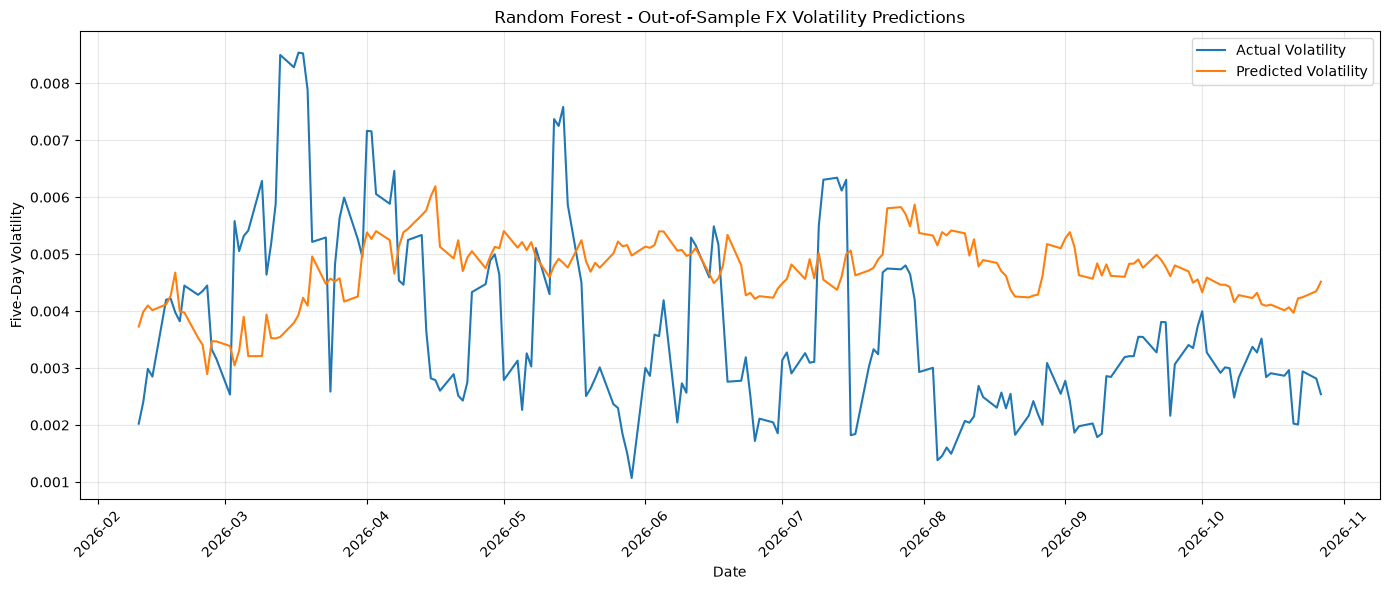

In [37]:
# Visualise test predictions
plt.figure(figsize=(14,6))
plt.plot(test_results["Date"],test_results["Actual Volatility"],label="Actual Volatility")
plt.plot(test_results["Date"],test_results["Predicted Volatility"],label="Predicted Volatility")
plt.title("Random Forest - Out-of-Sample FX Volatility Predictions")
plt.xlabel("Date")
plt.ylabel("Five-Day Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
# Create output directories 
output_dir = PROJECT_ROOT / "outputs" / "random_forest"
output_dir.mkdir(parents=True, exist_ok=True)
print("Output directory created:", output_dir)


Output directory created: c:\Users\alexb\fx-risk-intelligence\outputs\random_forest


In [39]:
# Save trained Random Forest model
model_path = output_dir / "random_forest_model.pkl"
joblib.dump(rf_model, model_path)
print("Model saved successfully.")

Model saved successfully.


In [41]:
# Save validation and test predictions
validation_results.to_csv( output_dir / "validation_predictions.csv", index=False)
test_results.to_csv(output_dir / "test_predictions.csv", index=False)
print("Prediction files saved successfully.")

Prediction files saved successfully.


In [43]:
# Save feature importance
feature_importance.to_csv( output_dir / "feature_importance.csv", index=False)
print("Feature improtance saved succesfully.")

Feature improtance saved succesfully.


In [44]:
# Create evaluation summary 
evaluation_results = pd.DataFrame({"Dataset": ["Validation", "Test"],"MAE": [mae, test_mae], "RMSE": [rmse, test_rmse], "R2": [r2, test_r2]})
evaluation_results.to_csv( output_dir / "model_evaluations.csv", index=False)
display(evaluation_results)
print("Evaluation reuslts saved successfully.")

,Dataset,MAE,RMSE,R2
0,Validation,0.001357,0.001677,-0.632058
1,Test,0.001768,0.002040,-0.648819


Evaluation reuslts saved successfully.
